# DAT171 Computer Assignment 1

In [1]:
import numpy as np

%config InlineBackend.figure_formats = ['svg']
%matplotlib inline
import matplotlib.pyplot as plt
from IPython.display import Video

from ca1_step2_solution import animate_particles
from ca1_step2_solution import plot_statistical_analysis

# Step 3: Simulation of particle dynamics

Here, in Step 3, you are tasked with writing a simulator that will produce results similar to the experimental data that we worked with in Step 1 and 2, but with more intricate dynamics. In the end you will repeat the statistical analysis from Step 2 on your own simulation results and study the effect of particle collisions on the particle dynamics.

The goal is to design a simulator that (approximately) describes both hard walls and collisions between particles. You want to simulate a system of 400 particles in two dimensions on the square $x,y \in [-1, 1]$ with a random initial condition.

Implement and hand in your simulation in a single file with the name `ca1_step3_solution.py`, please also hand in a plot of the statistical analysis with the name `ca1_step3_figure_summary.svg` and a movie of the final particle dynamics named `ca1_step3_movie4.mp4`.

## Particle system initialization

Generate a starting position array `r0` for the 400 particles using uniformly distributed random numbers on the interval $[-1, 1]$. Let `r0` be two dimensional, with the first index being the cartesian direction ($x$ and $y$) and the second index being the particle number. Similarly generate an initial velocity array `v0` with gaussian distributed $x$ and $y$ velocities having a variance equal to $0.1$.

Use the `np.random` module and its helper functions to generate the random numbers. Define the variables `N_particles` and `v_variance` to keep track of the number of particles and the velocity component variance.

The final shapes of `r0` and `v0` should thus be:

In [2]:
# -- SOLUTION

np.random.seed(1337) # We do not require fixing the random seed

N_particles = 400
shape = (2, N_particles)

# -- Uniformly distributed positions [-1, 1]
r0 = (2 * np.random.random(shape) - 1.)

# -- Normal distributed velocities
v_variance = 0.1
v0 = np.random.normal(loc=0., scale=v_variance, size=shape)

In [3]:
print(r0.shape, v0.shape)

(2, 400) (2, 400)


## Initial position visualization

As a sanity check plot the initial position using Matplotlib and its `plt.scatter` function. Make sure that there are no particles outside the $[-1 ,1]$ range.

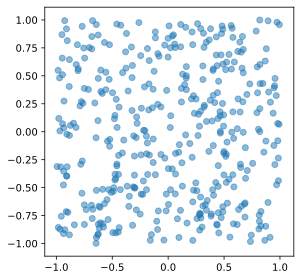

In [4]:
# -- Example

x0, y0 = r0[0, :], r0[1, :]
plt.scatter(x0, y0, alpha=0.5)
plt.axis('square')
plt.tight_layout()

## Time propagation

To simulate the propagation of time and the dynamics of the particles we are going to use a time discretized version of their equation of motion.

To this end we divide time in finite steps of length $\Delta t$ seconds. Then, assuming that we know the position $\vec{r}_i(t)$ and velocity $\vec{v}_i(t)$ of particle $i$ at time $t$, the position $\vec{r}_i(t + \Delta t)$ of particle $i$ at time $t + \Delta t$ is given by
$$
\vec{r}_i(t + \Delta t ) = \vec{r}_i(t) + \Delta t \cdot \vec{v}_i(t)
$$

Define the time discretization $\Delta t$ as the variable `time_step` and set it to 0.02 sec (which corresponds to 50 steps per second).

In [5]:
time_step = 0.02

Implement the function `time_propagation` that given the position `r` and velocity vector `v` at the current time computes the new positions one time step later. Use the function signature:
```python
def time_propagation(r, v, time_step):
    ...
    return r, v
```
Use the broadcasting features of NumPy and implement this using a single line of code.

In [6]:
# -- Solution

def time_propagation(r, v, time_step):
    r += time_step * v
    return r, v

## Simulation function

Lets now implements a function `simulate` that uses the `time_propagation` function to compute the time evolution of the particles for a given number of `time_steps`.

In order to make the `simulate` function reusable (in the coming steps) we want to pass both the `time_propagation` function as well as a general key-word-argument dictionary to the function. Here is a skeleton for the function to start from:
```python
def simulate(r0, v0, time_step, time_steps, update_function, **kwargs):
    # Allocate R and V
    # Initialize R[0] and V[0] using r0 and v0
    # Loop over all time steps and call 
    #   update_function(..., **kwargs)
    return R, V
```

In [7]:
# -- Solution

def simulate(r0, v0, time_step, time_steps, update_function, **kwargs):

    N = r0.shape[-1]
    R = np.empty((time_steps, 2, N))
    V = np.empty((time_steps, 2, N))

    R[0], V[0] = r0, v0

    for t in range(1, time_steps):
        print('--> time step:', t)
        R[t], V[t] = update_function(R[t - 1], V[t - 1], time_step, **kwargs)

    return R, V

Use your `simulate` function to compute the time propagation of the particles for 400 time steps.

In [8]:
simulation1 = simulate(
    r0, v0, time_step, time_steps=400, 
    update_function=time_propagation)

--> time step: 1
--> time step: 2
--> time step: 3
--> time step: 4
--> time step: 5
--> time step: 6
--> time step: 7
--> time step: 8
--> time step: 9
--> time step: 10
--> time step: 11
--> time step: 12
--> time step: 13
--> time step: 14
--> time step: 15
--> time step: 16
--> time step: 17
--> time step: 18
--> time step: 19
--> time step: 20
--> time step: 21
--> time step: 22
--> time step: 23
--> time step: 24
--> time step: 25
--> time step: 26
--> time step: 27
--> time step: 28
--> time step: 29
--> time step: 30
--> time step: 31
--> time step: 32
--> time step: 33
--> time step: 34
--> time step: 35
--> time step: 36
--> time step: 37
--> time step: 38
--> time step: 39
--> time step: 40
--> time step: 41
--> time step: 42
--> time step: 43
--> time step: 44
--> time step: 45
--> time step: 46
--> time step: 47
--> time step: 48
--> time step: 49
--> time step: 50
--> time step: 51
--> time step: 52
--> time step: 53
--> time step: 54
--> time step: 55
--> time step: 56
-

In order to visualize the time propagation import the `animate_particles` function from your solution to Step 2 and generate a movie of the particles.

In [9]:
animate_particles(simulation1[0], time_step, 'ca1_step3_movie1.mp4')

frame = 0
frame = 0
frame = 1
frame = 2
frame = 3
frame = 4
frame = 5
frame = 6
frame = 7
frame = 8
frame = 9
frame = 10
frame = 11
frame = 12
frame = 13
frame = 14
frame = 15
frame = 16
frame = 17
frame = 18
frame = 19
frame = 20
frame = 21
frame = 22
frame = 23
frame = 24
frame = 25
frame = 26
frame = 27
frame = 28
frame = 29
frame = 30
frame = 31
frame = 32
frame = 33
frame = 34
frame = 35
frame = 36
frame = 37
frame = 38
frame = 39
frame = 40
frame = 41
frame = 42
frame = 43
frame = 44
frame = 45
frame = 46
frame = 47
frame = 48
frame = 49
frame = 50
frame = 51
frame = 52
frame = 53
frame = 54
frame = 55
frame = 56
frame = 57
frame = 58
frame = 59
frame = 60
frame = 61
frame = 62
frame = 63
frame = 64
frame = 65
frame = 66
frame = 67
frame = 68
frame = 69
frame = 70
frame = 71
frame = 72
frame = 73
frame = 74
frame = 75
frame = 76
frame = 77
frame = 78
frame = 79
frame = 80
frame = 81
frame = 82
frame = 83
frame = 84
frame = 85
frame = 86
frame = 87
frame = 88
frame = 89
frame = 90

The result should look similar to: 

In [10]:
Video('ca1_step3_movie1.mp4', embed=True)

## Hard wall boundary collisions

Next we want to implement hard walls at $x = -1, 1$ and $y = -1, 1$ and cause the particles to bounce back if they "hit" the walls.

One way of accomplishing this is to
- check if the position coordinates ($x$ and $y$) are out of bounds and 
- the particle at the same time has a velocity component going in the wrong direction (relative to the "wall"). 

In this case change the sign of the corresponding velocity component ($v_x$ or $v_y$). This is an approximate but for our purposes sufficient treatment of the boundary collisions.

Write a function implements this with the arguments
```python
def boundary_collisions(r, v):
    ...
```
Use `numpy` boolean arrays for indexing so that each line of code treats all particles att the same time. Modifiy the velocity vector `v` in-place so that the function does not have to return anything. 

In [11]:
# -- Solution

def boundary_collisions(r, v):
    v[0, (r[0] > +1.) * (v[0] > 0.)] *= -1.
    v[0, (r[0] < -1.) * (v[0] < 0.)] *= -1.
    v[1, (r[1] > +1.) * (v[1] > 0.)] *= -1.
    v[1, (r[1] < -1.) * (v[1] < 0.)] *= -1.

Write a new `update_with_boundaries` function runs both the `time_propagation` and the new `boundary_collisions` and use it to simulate and animate the dynamis:

In [12]:
def update_with_boundaries(r, v, time_step):
    time_propagation(r, v, time_step)
    boundary_collisions(r, v)
    return r, v

simulation2 = simulate(
    r0, v0, time_step, time_steps=400, 
    update_function=update_with_boundaries)

animate_particles(simulation2[0], time_step, 'ca1_step3_movie2.mp4')

--> time step: 1
--> time step: 2
--> time step: 3
--> time step: 4
--> time step: 5
--> time step: 6
--> time step: 7
--> time step: 8
--> time step: 9
--> time step: 10
--> time step: 11
--> time step: 12
--> time step: 13
--> time step: 14
--> time step: 15
--> time step: 16
--> time step: 17
--> time step: 18
--> time step: 19
--> time step: 20
--> time step: 21
--> time step: 22
--> time step: 23
--> time step: 24
--> time step: 25
--> time step: 26
--> time step: 27
--> time step: 28
--> time step: 29
--> time step: 30
--> time step: 31
--> time step: 32
--> time step: 33
--> time step: 34
--> time step: 35
--> time step: 36
--> time step: 37
--> time step: 38
--> time step: 39
--> time step: 40
--> time step: 41
--> time step: 42
--> time step: 43
--> time step: 44
--> time step: 45
--> time step: 46
--> time step: 47
--> time step: 48
--> time step: 49
--> time step: 50
--> time step: 51
--> time step: 52
--> time step: 53
--> time step: 54
--> time step: 55
--> time step: 56
-

Your animation should look similar to this:

In [13]:
Video('ca1_step3_movie2.mp4', embed=True)

## Particle-particle collisions

Now we want to make the particles collide and bounce of eachother. Assume that all particles have equal and fixed radius and that they all have the same mass. We want the simulation to be physical and conserve total kinetic energy. Hence, the total momentum must be conserved in the collisions.

Implement an approximate collision algorithm that, at a given time step, 
- loops over all pairs of particles,
- check if they are closer to each other than two times `radius` and are travelling towards each other.
- If yes then modifiy their velocity vectors according to a momentum conserving collision.

*(Tip: Computing the velocity modification is simpler when thinking in a relative coordinate system where one particle is at rest. With the relative speed $\vec{v}_{ij} \equiv \vec{v}_i - \vec{v}_j$ the momentum conserving collision corresponds to modifying $\vec{v}_i \rightarrow \vec{v}_i - \vec{v}_{ij}$ and $\vec{v}_j \rightarrow \vec{v}_j + \vec{v}_{ij}$)*

Implement the collision algorithm as a separate function with the function signature
```python
def particle_collisions(r, v, radius):
    ...
```
and use it in the time evolution with a fixed radius of 0.05.

In [14]:
# -- Solution

def particle_collisions(r, v, radius):
    N = r.shape[-1]

    for i in range(N):
        for j in range(i + 1, N):
            r_ij = r[:, i] - r[:, j]
            v_ij = v[:, i] - v[:, j]
            if np.linalg.norm(r_ij) < 2 * radius and np.dot(v_ij, r_ij) < 0.:
                v[:, i] -= v_ij
                v[:, j] += v_ij

In [15]:
radius = 0.05

def update_with_interactions_slow(r, v, time_step, radius):
    time_propagation(r, v, time_step)
    boundary_collisions(r, v)
    particle_collisions(r, v, radius)
    return r, v

simulation3 = simulate(
    r0, v0, time_step, time_steps=40, 
    update_function=update_with_interactions_slow, radius=radius)

animate_particles(simulation3[0], time_step, 'ca1_step3_movie3.mp4')

--> time step: 1
--> time step: 2
--> time step: 3
--> time step: 4
--> time step: 5
--> time step: 6
--> time step: 7
--> time step: 8
--> time step: 9
--> time step: 10
--> time step: 11
--> time step: 12
--> time step: 13
--> time step: 14
--> time step: 15
--> time step: 16
--> time step: 17
--> time step: 18
--> time step: 19
--> time step: 20
--> time step: 21
--> time step: 22
--> time step: 23
--> time step: 24
--> time step: 25
--> time step: 26
--> time step: 27
--> time step: 28
--> time step: 29
--> time step: 30
--> time step: 31
--> time step: 32
--> time step: 33
--> time step: 34
--> time step: 35
--> time step: 36
--> time step: 37
--> time step: 38
--> time step: 39
frame = 0
frame = 0
frame = 1
frame = 2
frame = 3
frame = 4
frame = 5
frame = 6
frame = 7
frame = 8
frame = 9
frame = 10
frame = 11
frame = 12
frame = 13
frame = 14
frame = 15
frame = 16
frame = 17
frame = 18
frame = 19
frame = 20
frame = 21
frame = 22
frame = 23
frame = 24
frame = 25
frame = 26
frame = 27

As you might have noticed the simulation now takes a considerable ammount of time. The reason is that there are a large number of particle pairs to loop over in the collision detection algorithm. The number of pairs scales with the square of the number of particles!

For this reason just run a short simulation and make sure that your collision algorithm works correctly. We are going to reuse it in the next step in combination with a smart sorting algorithm that drastically improves both the speed and the scaling of the collision calculation.

Here is a short example of particles with collisions.

In [16]:
Video('ca1_step3_movie3.mp4', embed=True)

## Fast hard spheres

The simulation including collisions is actually rather slow. This is because looping over all pairs of particles scales like $N^2$, i.e. the square of the number of particles $N$.

There are, however, advanced space partitioning algorithms that performs the same operation with only $N \log N$ scaling, and `scipy` provides an implementation of such an algorithm.

Use the `KDTree` class in `scipy.spatial` to rapidly find all pairs of particles closer than two times the radius to each other.
- <https://docs.scipy.org/doc/scipy/reference/generated/scipy.spatial.cKDTree.html>

Use this in your collision detection algorithm and write an updated version with the function signature
```python
def particle_collisions_fast(r, v, radius):
    ...
```

In [17]:
# -- Solution

from scipy.spatial import KDTree

def particle_collisions_fast(r, v, radius):
    pairs = KDTree(r.T).query_pairs(2 * radius)

    for i, j in pairs:

        r_ij = r[:, i] - r[:, j]
        v_ij = v[:, i] - v[:, j]

        r_dot_v = np.dot(r_ij, v_ij)

        if r_dot_v < 0.:
            v[:, i] -= v_ij
            v[:, j] += v_ij

With the faster algorithm you can now easily run 1000 time steps and look at the dynamics. How does the animation differ from the particles without collisions?

In [18]:
def update_with_interactions_fast(r, v, time_step, radius):
    time_propagation(r, v, time_step)
    boundary_collisions(r, v)
    particle_collisions_fast(r, v, radius)
    return r, v

time_steps = 1000
simulation4 = simulate(
    r0, v0, time_step, time_steps, 
    update_function=update_with_interactions_fast, radius=radius)

animate_particles(simulation4[0], time_step, 'ca1_step3_movie4.mp4')

--> time step: 1
--> time step: 2
--> time step: 3
--> time step: 4
--> time step: 5
--> time step: 6
--> time step: 7
--> time step: 8
--> time step: 9
--> time step: 10
--> time step: 11
--> time step: 12
--> time step: 13
--> time step: 14
--> time step: 15
--> time step: 16
--> time step: 17
--> time step: 18
--> time step: 19
--> time step: 20
--> time step: 21
--> time step: 22
--> time step: 23
--> time step: 24
--> time step: 25
--> time step: 26
--> time step: 27
--> time step: 28
--> time step: 29
--> time step: 30
--> time step: 31
--> time step: 32
--> time step: 33
--> time step: 34
--> time step: 35
--> time step: 36
--> time step: 37
--> time step: 38
--> time step: 39
--> time step: 40
--> time step: 41
--> time step: 42
--> time step: 43
--> time step: 44
--> time step: 45
--> time step: 46
--> time step: 47
--> time step: 48
--> time step: 49
--> time step: 50
--> time step: 51
--> time step: 52
--> time step: 53
--> time step: 54
--> time step: 55
--> time step: 56
-

In [19]:
Video('ca1_step3_movie4.mp4', embed=True)

## Statistical analysis of interacting particles

Use your last longer simulation of particles including hard walls and the fast collision algorithm and repeat the statistical analysis you performed in Step 2. Import your `plot_statistical_analysis` function from the `ca1_step2_solution.py` file and run it on the simulation data. Store the resulting plot in `ca1_step3_figure_summary.svg`.

Questions:
- Check that your simulation conserves total kinetic energy.
- What are the qualitative differences in 
  - the position and velocity histograms, and
  - the pair distribution function?

## Computer Assignment 1 Step 3: Deliverables¶

Hand in your simulation in 
- a single file with the name `ca1_step3_solution.py`,
- a plot of the statistical analysis named `ca1_step3_figure_summary.svg` and
- a movie of the final particle dynamics named `ca1_step3_movie4.mp4`.

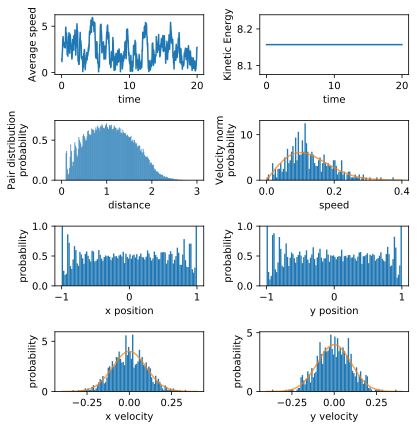

In [20]:
plot_statistical_analysis(
    *simulation4, time_step, 'ca1_step3_figure_summary.svg')

Answers:

- With interactions the particles avoid each other, so the pair distribution function is zero up to two times the particule radius.

- At high enough density (i.e. large enough radius) the system enters a liquid phase, characterized by peaks in the pair distribution function.

- With hard wall boundaries we get more order at the boundaries than in the center of the simulation area, as seen in the pleaks in the position histograms.